# **Installing libraries**

In [ ]:
!pip install chembl_webresource_client==0.10.8

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 5.7 MB/s eta 0:00:00
  Attempting uninstall: attrs
    Found existing installation: attrs 26.1.0
    Uninstalling attrs-26.1.0:
      Successfully uninstalled attrs-26.1.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jsonschema 4.26.0 requires attrs>=22.2.0, but you have attrs 21.4.0 which is incompatible.
referencing 0.37.0 requires attrs>=22.2.0, but you have attrs 21.4.0 which is incompatible.


# **Importing libraries**

In [ ]:
import pandas as pd
from chembl_webresource_client.new_client import new_client

/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


#**Search for target protein**

**Target search for coronavirus**

In [ ]:
from chembl_webresource_client.new_client import new_client
#Target search for coronavirus
target=new_client.target
target_query=target.search('coronavirus')
targets=pd.DataFrame.from_dict(target_query)
targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Coronavirus,Coronavirus,17.0,False,CHEMBL613732,[],ORGANISM,11119
1,[],Feline coronavirus,Feline coronavirus,14.0,False,CHEMBL612744,[],ORGANISM,12663
2,[],Murine coronavirus,Murine coronavirus,14.0,False,CHEMBL5209664,[],ORGANISM,694005
3,[],Canine coronavirus,Canine coronavirus,14.0,False,CHEMBL5291668,[],ORGANISM,11153
4,[],Bovine coronavirus,Bovine coronavirus,14.0,False,CHEMBL6066646,[],ORGANISM,11128
5,[],Human coronavirus 229E,Human coronavirus 229E,13.0,False,CHEMBL613837,[],ORGANISM,11137
6,[],Human coronavirus OC43,Human coronavirus OC43,13.0,False,CHEMBL5209665,[],ORGANISM,31631
7,[],unidentified human coronavirus,unidentified human coronavirus,13.0,False,CHEMBL6195448,[],ORGANISM,694448
8,[],Human coronavirus NL63,Human coronavirus NL63,13.0,False,CHEMBL6195756,[],ORGANISM,277944
9,[],Middle East respiratory syndrome-related coron...,Middle East respiratory syndrome-related coron...,9.0,False,CHEMBL4296578,[],ORGANISM,1335626


**Select and retrieve bioactivity data for SARS coronavirus 3C-like proteinase(fourth entry)**

We will assign the fourth entry(which corresponds to the target protein,coronavirus 3C -like proteinase) to the selected_target

In [ ]:
selected_target='CHEMBL6067603'
selected_target

'CHEMBL6067603'

Here,we will retrieve only bioactivity data for coronavirus 3C-like proteinase (CHEMBL6066646) that are reported as IC50 values in nM (nanomolar) unit

In [ ]:
activity=new_client.activity
res=activity.filter(target_chembl_id=selected_target)


In [ ]:
df=pd.DataFrame.from_dict(res)


In [ ]:
df.head(3)

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25609271,"[{'comments': None, 'relation': '<=', 'result_...",CHEMBL5360292,PROTAC activity at CRBN/C-terminal HA epitope-...,B,None,None,BAO_0000375,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,Active,None,Activity,None,None,None,None
1,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25609272,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL5360293,PROTAC activity at CRBN/C-terminal HA epitope-...,B,None,None,BAO_0000375,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,Active,None,Activity,None,None,None,None
2,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872060,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL5513036,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,uM,UO_0000065,None,0.62


Finally we will save the resulting bioactivity data to a csv file bioactivity_data.csv

In [ ]:
df.to_csv('bioactivity_data.csv',index=False)

**Copying files to Goodgle Drive**

Firstly,we need to mount Google Drive into collab so that we can have access to our Google drive from

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive/', force_remount=True)

Mounted at /content/gdrive/


Next, we create a data folder in our Colab Notebooks folder on google

In [ ]:
! mkdir "/content/gdrive/My Drive/Colab Notebooks/data"

mkdir: cannot create directory ‘/content/gdrive/My Drive/Colab Notebooks/data’: File exists


In [ ]:
! cp bioactivity_data.csv "/content/gdrive/My Drive/Colab Notebooks/data2"

In [ ]:
! ls -l "/content/gdrive/My Drive/Colab Notebooks/data2"

total 42
-rw------- 1 root root 37658 Oct 13 12:08 bioactivity_data.csv
-rw------- 1 root root  4253 Oct 11 18:04 bioactivity_preprocessed_data.csv


In [ ]:
! ls "/content/gdrive/My Drive/Colab Notebooks"

data						 Untitled18.ipynb
data2						 Untitled19.ipynb
Drug_Discovery_Using_ML_and_Data_Analysis.ipynb  Untitled1.ipynb
First_ML_project.ipynb				 Untitled20.ipynb
Untitled					 Untitled2.ipynb
Untitled0.ipynb					 Untitled3.ipynb
Untitled10.ipynb				 Untitled4.ipynb
Untitled11.ipynb				 Untitled5.ipynb
Untitled12.ipynb				 Untitled6.ipynb
Untitled13.ipynb				 Untitled7.ipynb
Untitled14.ipynb				 Untitled8.ipynb
Untitled15.ipynb				 Untitled9.ipynb
Untitled16.ipynb				 VF_Cor_TP3_Python.ipynb
Untitled17.ipynb


Let's see the CSV files that we have so far

In [ ]:
! ls

bioactivity_data.csv  gdrive  results.zip  sample_data


In [ ]:
! head bioactivity_data.csv

action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,bao_label,canonical_smiles,data_validity_comment,data_validity_description,document_chembl_id,document_journal,document_year,ligand_efficiency,modality,molecule_chembl_id,molecule_pref_name,parent_molecule_chembl_id,pchembl_value,potential_duplicate,qudt_units,record_id,relation,src_id,standard_flag,standard_relation,standard_text_value,standard_type,standard_units,standard_upper_value,standard_value,target_chembl_id,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
"{'action_type': 'DEGRADER', 'description': 'Binds to or antagonizes a receptor, leading to its degradation', 'parent_type': 'NEGATIVE MODULATOR'}",,25609271,"[{'comments': None, 'relation': '<=', 'result_flag': 0, 'standard_relation': '<=', 'standard_text_value': None, 'standard_type': 'DOSE', 'stan

#**Handling missing data**

If any compounds has missing value for the standard_value column then drop it

In [ ]:
df2 = df[df.standard_value.notna()]
df2

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
2,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872060,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL5513036,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,uM,UO_0000065,None,0.62
3,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872061,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL5513036,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,uM,UO_0000065,None,0.25
4,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872062,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL5513036,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,uM,UO_0000065,None,2.15
5,None,None,25872081,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
6,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872082,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
7,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872083,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
8,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872084,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
9,None,None,25872085,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
10,None,None,25872086,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0
11,"{'action_type': 'DEGRADER', 'description': 'Bi...",None,25872087,[],CHEMBL5513038,PROTAC activity at SARS-CoV-2 Main protease/CR...,B,None,None,BAO_0000188,...,Severe acute respiratory syndrome coronavirus 2,Protein cereblon/Replicase polyprotein 1ab,2697049,None,None,EC50,nM,UO_0000065,None,100.0


#**Data pre-processing of the bioactivity data**

**Labeling compounds as either being active,inactive or intermediate**

In [ ]:
bioactivity_class= []
for i in df2.standard_value:
  if float(i)>=10000:
    bioactivity_class.append("inactive")
  elif float(i)<=1000:
    bioactivity_class.append("active")
  else:
    bioactivity_class.append("intermediate")
bioactivity_class

['active',
 'active',
 'intermediate',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active',
 'active']

#**Iterate the molecule_chembl_id to a list**

In [ ]:
mol_cid=[]
for i in df2.molecule_chembl_id:
  mol_cid.append(i)
#mol_cid

#**Iterate standard_value to a list**

In [ ]:
standard_value = []
for i in df2.standard_value:
  standard_value.append(i)
standard_value


['620.0',
 '250.0',
 '2150.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '100.0',
 '27.6',
 '26.7',
 '22.4',
 '14.7',
 '10.9',
 '419.0',
 '296.0',
 '431.0']

**Iterate the molecule_cheml_id to a list**

In [ ]:
canonical_smiles = []
for i in df2.canonical_smiles:
  canonical_smiles.append(i)

#**Combine the 4 lists into a dataframe**

In [ ]:
data_tuples = list(zip(mol_cid, canonical_smiles , bioactivity_class, standard_value))
df3=pd.DataFrame(data_tuples,columns=['molecule_chembl_id','canonical_smiles','bioactivity_class','standard_value'])
df3

,molecule_chembl_id,canonical_smiles,bioactivity_class,standard_value
0,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,active,620.0
1,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,active,250.0
2,CHEMBL5542152,Cc1c(COC(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](C[C@@H...,intermediate,2150.0
3,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,active,100.0
4,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,active,100.0
5,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,active,100.0
6,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,active,100.0
7,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,active,100.0
8,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,active,100.0
9,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,active,100.0


#***Alternative method***

In [ ]:
selection=['molecule_chembl_id','canonical_smiles','standard_value']
df3=df2[selection]
df3

,molecule_chembl_id,canonical_smiles,standard_value
2,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,620.0
3,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,250.0
4,CHEMBL5542152,Cc1c(COC(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](C[C@@H...,2150.0
5,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,100.0
6,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,100.0
7,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,100.0
8,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,100.0
9,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,100.0
10,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,100.0
11,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,100.0


Saves dataframe to CSV file

In [ ]:
df3.to_csv('bioactivity_preprocessed_data.csv',index=False)

In [ ]:
! ls -l

total 60
-rw-r--r-- 1 root root 37658 Oct 13 12:07 bioactivity_data.csv
-rw-r--r-- 1 root root  4253 Oct 13 12:08 bioactivity_preprocessed_data.csv
drwx------ 5 root root  4096 Oct 13 12:07 gdrive
-rw-r--r-- 1 root root    22 Oct 13 12:06 results.zip
drwxr-xr-x 1 root root  4096 Oct  2 13:50 sample_data


In [ ]:
! cp bioactivity_preprocessed_data.csv "/content/gdrive/My Drive/Colab Notebooks/data2"

Let's copy to the Google Drive

In [ ]:
! ls "/content/gdrive/My Drive/Colab Notebooks/data2"

bioactivity_data.csv  bioactivity_preprocessed_data.csv


#***Part 2 : Exploratory data analysis***

In [ ]:
! wget https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh

--2026-10-13 12:08:37--  https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh
Resolving repo.anaconda.com (repo.anaconda.com)... 104.16.191.158, 104.16.32.241, 2606:4700::6810:bf9e, ...
Connecting to repo.anaconda.com (repo.anaconda.com)|104.16.191.158|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 85055499 (81M) [application/x-sh]
Saving to: ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’

Miniconda3-py37_4.8 100%[===================>]  81.12M   221MB/s    in 0.4s    

2026-10-13 12:08:37 (221 MB/s) - ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’ saved [85055499/85055499]



In [ ]:
! chmod +x Miniconda3-py37_4.8.2-Linux-x86_64.sh

In [ ]:
! bash ./Miniconda3-py37_4.8.2-Linux-x86_64.sh -b -f -p /usr/local

PREFIX=/usr/local
Unpacking payload ...
Solving environment: | / done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - _libgcc_mutex==0.1=main
    - asn1crypto==1.3.0=py37_0
    - ca-certificates==2020.1.1=0
    - certifi==2019.11.28=py37_0
    - cffi==1.14.0=py37h2e261b9_0
    - chardet==3.0.4=py37_1003
    - conda-package-handling==1.6.0=py37h7b6447c_0
    - conda==4.8.2=py37_0
    - cryptography==2.8=py37h1ba5d50_0
    - idna==2.8=py37_0
    - ld_impl_linux-64==2.33.1=h53a641e_7
    - libedit==3.1.20181209=hc058e9b_0
    - libffi==3.2.1=hd88cf55_4
    - libgcc-ng==9.1.0=hdf63c60_0
    - libstdcxx-ng==9.1.0=hdf63c60_0
    - ncurses==6.2=he6710b0_0
    - openssl==1.1.1d=h7b6447c_4
    - pip==20.0.2=py37_1
    - pycosat==0.6.3=py37h7b6447c_0
    - pycparser==2.19=py37_0
    - pyopenssl==19.1.0=py37_0
    - pysocks==1.7.1=py37_0
    - python==3.7.6=h0371630_2
    - readline==7.0=h7b6447c_5
    - requests==2.22.0=py37_1
    - ruamel_yaml==0.15.8

In [ ]:
!pip install rdkit-pypi

     |████████████████████████████████| 29.2 MB 1.6 MB/s 
     |████████████████████████████████| 3.3 MB 46.3 MB/s 
     |████████████████████████████████| 15.7 MB 44.6 MB/s 


In [ ]:
import sys
sys.path.append('/usr/local/lib/python3.7/site-packages/')

In [ ]:
!pip install rdkit chembl_webresource_client pandas numpy

     |████████████████████████████████| 29.5 MB 408 kB/s 
     |████████████████████████████████| 55 kB 4.0 MB/s 
     |████████████████████████████████| 11.3 MB 26.9 MB/s 
ERROR: Could not find a version that satisfies the requirement requests-cache~=1.2 (from chembl_webresource_client) (from versions: 0.1.0, 0.1.1, 0.1.2, 0.1.3, 0.2.0, 0.2.1, 0.3.0, 0.4.0, 0.4.1, 0.4.2, 0.4.3, 0.4.4, 0.4.5, 0.4.6, 0.4.7, 0.4.8, 0.4.9, 0.4.10, 0.4.11, 0.4.12, 0.4.13, 0.5.0, 0.5.1, 0.5.2, 0.6.0, 0.6.1, 0.6.2, 0.6.3, 0.6.4, 0.7.0, 0.7.1, 0.7.2, 0.7.3, 0.7.4, 0.7.5, 0.8.0, 0.8.1, 0.9.0, 0.9.1, 0.9.2, 0.9.3, 0.9.4, 0.9.5, 0.9.6, 0.9.7, 0.9.8, 1.0.0a0, 1.0.0a1, 1.0.0a2, 1.0.0b0, 1.0.0b1, 1.0.0, 1.0.1, 1.1.0, 1.1.1)
ERROR: No matching distribution found for requests-cache~=1.2 (from chembl_webresource_client)


#**Load bioactivity data**

In [ ]:
import pandas as pd

In [ ]:
df =pd.read_csv('bioactivity_preprocessed_data.csv')

#**Calculate Lipinski descriptors**

Lipinski's Rule (Rule-of-Five):

*  Molecular weight < 500 Dalton  
*  Octanol-water partition coefficient (LogP) < 5  
*   Hydrogen bond donors < 5   Hydrogen bond acceptors < 10





#**Import librairies**

In [ ]:
import sys
# Nettoyer sys.path de tout résidu de python3.7 pour éviter les conflits de binaires
sys.path = [p for p in sys.path if 'python3.7' not in p]

# Installer rdkit en ciblant explicitement l'exécutable Python actif du noyau Colab
!{sys.executable} -m pip install rdkit

import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 65.0 MB/s eta 0:00:00


**Calculate descriptors**

In [ ]:
def lipinski(smiles, verbose=False):
  moldata = []
  for elem in smiles:
    mol = Chem.MolFromSmiles(elem)
    moldata.append(mol)

  baseData = []
  for mol in moldata:
    if mol is None:
      continue
    desc_MolWt = Descriptors.MolWt(mol)
    desc_MolLogP = Descriptors.MolLogP(mol)
    desc_NumHDonors = Lipinski.NumHDonors(mol)
    desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)

    row = [desc_MolWt, desc_MolLogP, desc_NumHDonors, desc_NumHAcceptors]
    baseData.append(row)

  columnNames = ["MW", "LogP", "NumHDonors", "NumHAcceptors"]
  descriptors = pd.DataFrame(data=baseData, columns=columnNames)
  return descriptors

In [ ]:
import pandas as pd

# Charger les données si la variable 'df' n'est pas définie
try:
    df
except NameError:
    df = pd.read_csv('bioactivity_preprocessed_data.csv')

# Calculer les descripteurs de Lipinski
df_lipinski = lipinski(df.canonical_smiles)
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,949.032,0.71802,6,15
1,887.948,1.59030,6,14
2,971.976,-4.41418,6,18
3,845.155,1.64600,3,11
4,859.182,2.03610,3,11
5,873.209,2.42620,3,11
6,887.236,2.81630,3,11
7,901.263,3.20640,3,11
8,915.290,3.59650,3,11
9,875.181,1.27250,3,12


#**Combine DataFrames**

Let's take a look at the 2 DataFrames that will be combined

In [ ]:
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,949.032,0.71802,6,15
1,887.948,1.59030,6,14
2,971.976,-4.41418,6,18
3,845.155,1.64600,3,11
4,859.182,2.03610,3,11
5,873.209,2.42620,3,11
6,887.236,2.81630,3,11
7,901.263,3.20640,3,11
8,915.290,3.59650,3,11
9,875.181,1.27250,3,12


In [ ]:
df

,molecule_chembl_id,canonical_smiles,standard_value
0,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,620.0
1,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,250.0
2,CHEMBL5542152,Cc1c(COC(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](C[C@@H...,2150.0
3,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,100.0
4,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,100.0
5,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,100.0
6,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,100.0
7,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,100.0
8,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,100.0
9,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,100.0


#**Convert IC50 to pIC50**
To allow IC50 to be more uniformly distibuted , we will convert IC50 to the negative logarithmic scale which is essentially -log10(IC50)
This custom function pIC50() will accept DataFrames as input and will:

*   Take the IC50 values from the standard_value column and converts it from nM to M by multiplying the value by 10(-9)
*   Take the molar value and apply -log10
*   Delete the standard_value column and create a new pIC50 column





In [ ]:
import numpy as np

def pIC50(input):
  pIC50 = []

  for i in input['standard_value_norm']:
    # Convertir de nM à M et calculer le -log10
    molar = float(i) * (10**-9)
    pIC50.append(-np.log10(molar))

  # On ajoute la colonne et on supprime l'ancienne en DEHORS de la boucle for
  input['pIC50'] = pIC50
  x = input.drop(columns=['standard_value_norm'])
  return x

Point ro note : Values greater then 100,000,000 will be fixed at 100,000,000 otherwise the negative logarithmic value will become negative

In [ ]:
import pandas as pd

# Combiner les deux DataFrames df et df_lipinski côte à côte
df_combined = pd.concat([df, df_lipinski], axis=1)

# Afficher la description statistique de la colonne standard_value
df_combined.standard_value.describe()

,standard_value
count,29.000000
mean,209.251724
std,397.799621
min,10.900000
25%,100.000000
50%,100.000000
75%,100.000000
max,2150.000000


In [ ]:
-np.log10((10** -9)*100000000)

np.float64(1.0)

In [ ]:
-np.log10((10**-9)*10000000000)

np.float64(-1.0)

In [ ]:
def norm_value(input):
  norm=[]

  for i in input['standard_value']:
    if i>100000000:
      i=100000000
    norm.append(i)
  input['standard_value_norm']=norm
  x=pIC50(input)

We will first apply the norm_value()function so that the values in the standard_value column is normalized

In [ ]:
def norm_value(input_df):
  norm = []

  for i in input_df['standard_value']:
    val = float(i)
    if val > 100000000:
      val = 100000000
    norm.append(val)
  input_df['standard_value_norm'] = norm
  x = pIC50(input_df)
  return x

# Recréer df_combined de sécurité si elle n'est pas définie dans l'espace de nom
try:
    df_combined
except NameError:
    import pandas as pd
    df_combined = pd.concat([df, df_lipinski], axis=1)

df_norm = norm_value(df_combined)
df_norm

,molecule_chembl_id,canonical_smiles,standard_value,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,620.0,949.032,0.71802,6,15,6.207608
1,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,250.0,887.948,1.59030,6,14,6.602060
2,CHEMBL5542152,Cc1c(COC(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](C[C@@H...,2150.0,971.976,-4.41418,6,18,5.667562
3,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,100.0,845.155,1.64600,3,11,7.000000
4,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,100.0,859.182,2.03610,3,11,7.000000
5,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,100.0,873.209,2.42620,3,11,7.000000
6,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,100.0,887.236,2.81630,3,11,7.000000
7,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,100.0,901.263,3.20640,3,11,7.000000
8,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,100.0,915.290,3.59650,3,11,7.000000
9,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,100.0,875.181,1.27250,3,12,7.000000


In [ ]:
# df_norm contient déjà les calculs de pIC50 et a déjà nettoyé standard_value_norm
df_final = df_norm
df_final

,molecule_chembl_id,canonical_smiles,standard_value,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,620.0,949.032,0.71802,6,15,6.207608
1,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,250.0,887.948,1.59030,6,14,6.602060
2,CHEMBL5542152,Cc1c(COC(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](C[C@@H...,2150.0,971.976,-4.41418,6,18,5.667562
3,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,100.0,845.155,1.64600,3,11,7.000000
4,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,100.0,859.182,2.03610,3,11,7.000000
5,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,100.0,873.209,2.42620,3,11,7.000000
6,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,100.0,887.236,2.81630,3,11,7.000000
7,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,100.0,901.263,3.20640,3,11,7.000000
8,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,100.0,915.290,3.59650,3,11,7.000000
9,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,100.0,875.181,1.27250,3,12,7.000000


In [ ]:
df_final.pIC50.describe()

,pIC50
count,29.000000
mean,6.976787
std,0.472130
min,5.667562
25%,7.000000
50%,7.000000
75%,7.000000
max,7.962574


#**Removing the 'intermediate class from our data set**

Here , we will be removing the intermediate class from our data set

In [ ]:
# Recréer la colonne bioactivity_class manquante dans df_final
bioactivity_class = []
for i in df_final.standard_value:
  val = float(i)
  if val >= 10000:
    bioactivity_class.append('inactive')
  elif val <= 1000:
    bioactivity_class.append('active')
  else:
    bioactivity_class.append('intermediate')

df_final['bioactivity_class'] = bioactivity_class

# Filtrer pour exclure la classe 'intermediate'
df_2class = df_final[df_final['bioactivity_class'] != 'intermediate']
df_2class

,molecule_chembl_id,canonical_smiles,standard_value,MW,LogP,NumHDonors,NumHAcceptors,pIC50,bioactivity_class
0,CHEMBL5567880,Cc1c(COC2CCC(OC(=O)N[C@@H](CC(C)C)C(=O)N[C@H](...,620.0,949.032,0.71802,6,15,6.207608,active
1,CHEMBL5564884,CC(C)C[C@H](NC(=O)Oc1ccc(OCc2cn(CCCCCOCC(=O)Nc...,250.0,887.948,1.59030,6,14,6.602060,active
3,CHEMBL5563062,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCC(=O)Nc5cccc...,100.0,845.155,1.64600,3,11,7.000000,active
4,CHEMBL5559064,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCC(=O)Nc5ccc...,100.0,859.182,2.03610,3,11,7.000000,active
5,CHEMBL5557061,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCC(=O)Nc5cc...,100.0,873.209,2.42620,3,11,7.000000,active
6,CHEMBL5560675,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCC(=O)Nc5c...,100.0,887.236,2.81630,3,11,7.000000,active
7,CHEMBL5556057,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCC(=O)Nc5...,100.0,901.263,3.20640,3,11,7.000000,active
8,CHEMBL5562311,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCCCCCCC(=O)Nc...,100.0,915.290,3.59650,3,11,7.000000,active
9,CHEMBL5558922,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCC(=O)Nc5cc...,100.0,875.181,1.27250,3,12,7.000000,active
10,CHEMBL5555021,Cn1cc2cc(/N=c3\[nH]c(=O)n(Cc4cn(CCOCCOCC(=O)Nc...,100.0,919.234,1.28910,3,13,7.000000,active


#**Exploratory Data Analysis (Chemical Space Analysis) via Lipinski descriptors**

**Import library**

In [ ]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

**Frequency plot of the 2 bioactivity classes**

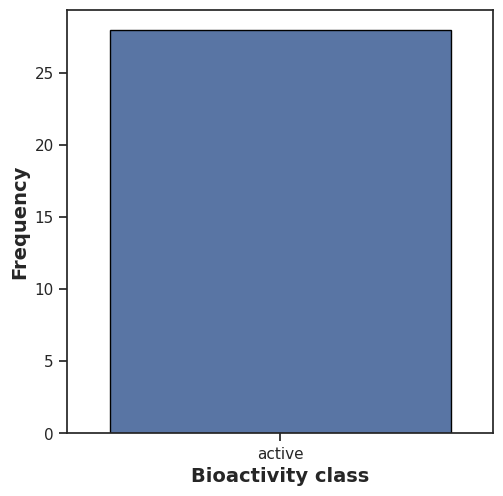

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='bioactivity_class', data=df_2class, edgecolor='black')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.pdf')

**Scatter plot of MW versus LogP**

It can be seen that the 2 bioactivity classes are spanning similar chemichal spaces as evident by the scatter plot of MW vs LogP

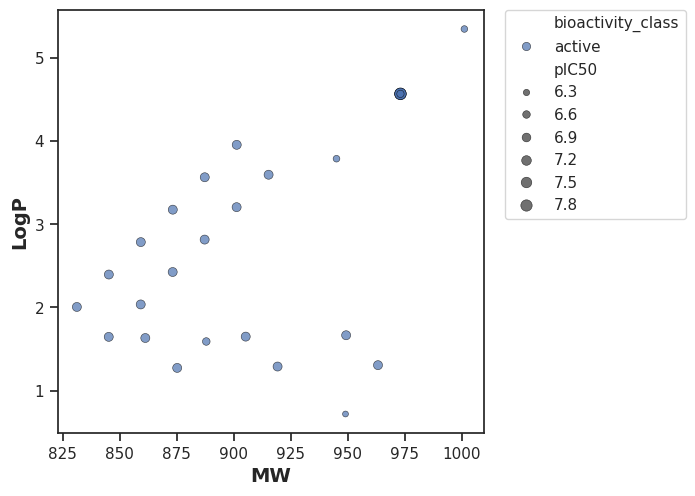

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='MW', y='LogP', data=df_2class, hue='bioactivity_class', size='pIC50', edgecolor='black',alpha=0.7)

plt.xlabel('MW', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05,1),loc=2, borderaxespad=0)
plt.savefig('plot_MW_vs_LogP.pdf')

#**Box plot**

**pIC50 value**

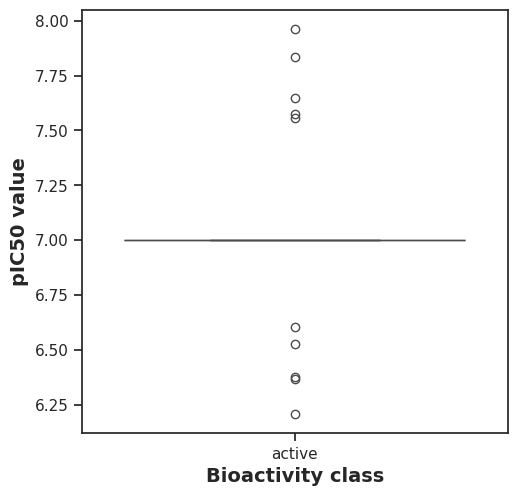

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_2class)
plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')
plt.savefig('plot_ic50.pdf')

**Statical analysis |Mann-Whitney U Test**

In [ ]:
from os import stat
def mannwhitney(descriptor, verbose=False):
  #gets all active and inactive as lists
  from numpy.random import seed
  from numpy.random import randn
  from scipy.stats import mannwhitneyu
  seed(1)

  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  active = df[df['bioactivity_class'] == 'active']
  active=active[descriptor]

  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  inactive = df[df['bioactivity_class'] == 'inactive']
  inactive=inactive[descriptor]
  #compare samples
  stat, p = mannwhitneyu(active, inactive)
  #interpret
  alpha = 0.05
  if p > alpha:
    interpretation = 'Same distribution (fail to reject H0)'
  else:
    interpretation = 'Different distribution (reject H0)'

  results = pd.DataFrame({'Descriptor':descriptor,
                          'Statistics':stat,
                          'p':p,
                          'alpha':alpha,
                          'Interpretation':interpretation}, index=[0])
  filename = 'mannwhitneyu_' + descriptor + '.csv'
  results.to_csv(filename)

  return results




In [ ]:
mannwhitney('pIC50')
#

/tmp/ipykernel_3171/955476323.py:19: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = mannwhitneyu(active, inactive)


,Descriptor,Statistics,p,alpha,Interpretation
0,pIC50,NaN,NaN,0.05,Different distribution (reject H0)


#**MW**

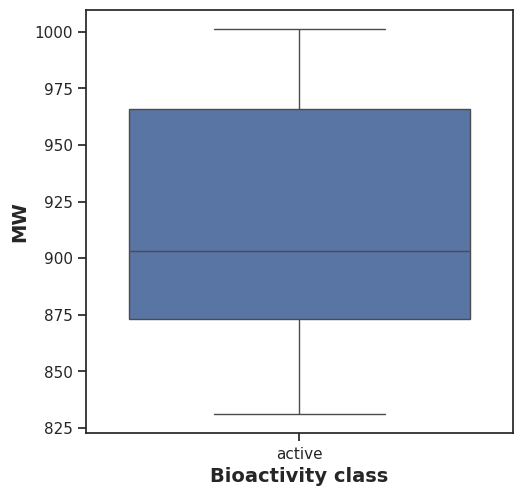

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'MW', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('MW', fontsize=14, fontweight='bold')

plt.savefig('plot_MW.pdf')

**Statical analysis | Mann-Whitney U Test**

In [ ]:
mannwhitney('LogP')

/tmp/ipykernel_3171/955476323.py:19: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = mannwhitneyu(active, inactive)


,Descriptor,Statistics,p,alpha,Interpretation
0,LogP,NaN,NaN,0.05,Different distribution (reject H0)


#**NumHDonors**

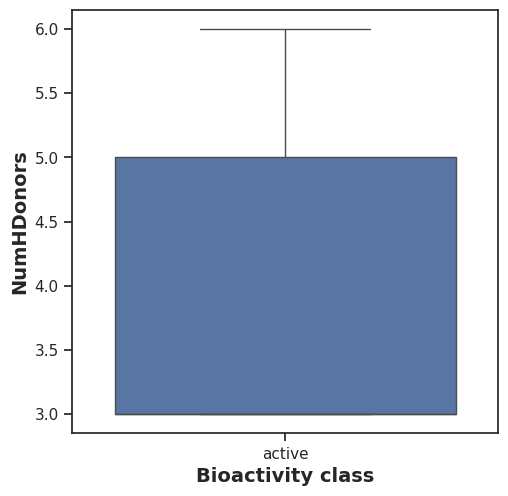

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'NumHDonors', data = df_2class)
plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')
plt.savefig('plot_NumHDonors.pdf')

In [ ]:
mannwhitney('NumHDonors')

/tmp/ipykernel_34426/1440959602.py:19: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = mannwhitneyu(active, inactive)


,Descriptor,Statistics,p,alpha,Interpretation
0,NumHDonors,NaN,NaN,0.05,Different distribution (reject H0)


**Interpretation of Statical
Results**

**Box Plots**
**pIC50 values**
Taking a look at pIC50 values, the actives and incatives displayed statically significant difference ,which to be expected since threshold values (IC50 < 1,00 nM = Actives while IC50 > 10,000 nM = Inactives,corresponding to pIC50 > 6 = Actives and pIC50 < 5 = Inactives) were used to define actives and inactives.
**Lipinski's descriptors**
Of the 4 Lipiniski's descriptors (MW,NumJDONORS and NumHAcceptors) shows statically significant difference between actives and inactives.

#**Zip files**

In [ ]:
! zip -r results.zip . -i * .csv * .pdf

	zip warning: name not matched: gdrive/MyDrive/Classroom/Atelier Framework LSI2/projet_framework.zip
Scanning files .
  adding: bioactivity_preprocessed_data.csv (deflated 87%)
  adding: plot_bioactivity_class.pdf (deflated 39%)
  adding: mannwhitneyu_LogP.csv (deflated 6%)
  adding: bioactivity_data.csv (deflated 92%)
  adding: plot_ic50.pdf (deflated 37%)
  adding: plot_MW_vs_LogP.pdf (deflated 25%)
  adding: plot_NumHDonors.pdf (deflated 38%)
  adding: Miniconda3-py37_4.8.2-Linux-x86_64.sh (deflated 0%)
  adding: mannwhitneyu_pIC50.csv (deflated 9%)
  adding: plot_MW.pdf (deflated 39%)
